# Intensity Interferometry / Magnification Fisher-Matrix Analysis

Parameterised diagnostic notebook.  Set `MASS`, `GRID_EXTENT`, `GRID_SIZE` in the
config cell below, then **Run All**.

* Calls `run_II_fisher.py`, `run_mag_fisher.py`, `run_centroid.py` (once) if the
  output files are missing.
* Uses the Gram-matrix Fisher (`F = Jᵀ J / σ²`) — guaranteed positive semi-definite.


In [188]:
# ── Configuration ─────────────────────────────────────────────────────────────
MASS        = 0.1     # lens mass in solar masses
GRID_EXTENT = 10      # grid half-extent in units of theta_E
GRID_SIZE   = 20      # grid points per axis (N×N)


In [189]:
import jax
jax.config.update("jax_enable_x64", True)

import os, re, subprocess, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors
from scipy.interpolate import RegularGridInterpolator, RectBivariateSpline

NOTEBOOK_DIR = os.getcwd()   # Jupyter runs from the notebook directory
if NOTEBOOK_DIR not in sys.path:
    sys.path.insert(0, NOTEBOOK_DIR)

from II_funcs import (
    G, c, D_s, D_l, D_ls, z_l, rad_to_arcsec,
    kappa_bulk, gamma1, gamma2, theta_500,
    parameter_uncertainties,
)

plt.rcParams['mathtext.fontset'] = "cm"
plt.rcParams['font.family']      = "serif"
plt.rcParams['mathtext.default'] = 'regular'


In [190]:
# ─── File-loading helpers ──────────────────────────────────────────────────────

def load_file(file, skip_lines=0, force_shape=(4, 4)):
    """
    Parse *_II.txt output from run_II_fisher.py.

    Each line:  [px py]  unc_r  unc_m  unc_x  unc_y  [[4x4 cov_matrix]]

    Returns
    -------
    out_xval : (N,2) pixel positions
    out_rad, out_mass, out_x, out_y : 1-D uncertainty arrays
    out_mat  : list of (4,4) covariance matrices
    """
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file) as fh:
        raw = "".join(fh.readlines()[skip_lines:])

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y, out_mat = [], [], [], [], []

    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header = raw[prev_end:m.start()].strip()
        prev_end = m.end()
        toks = token_re.findall(header)
        if not toks:
            raise ValueError(f"No tokens in header before matrix at pos {m.start()}")
        vals = [np.nan if t.lower() == 'nan' else float(t) for t in toks]
        if len(vals) == 6:
            x1, x2, r, ma, xp, yp = vals
        elif len(vals) == 5:
            x1, x2 = vals[0], np.nan
            r, ma, xp, yp = vals[1], vals[2], vals[3], vals[4]
        else:
            raise ValueError(f"Unexpected {len(vals)} header tokens: {toks!r}")
        out_x1.append(x1); out_x2.append(x2)
        out_rad.append(r);  out_mass.append(ma)
        out_x.append(xp);   out_y.append(yp)
        mat_vals = [np.nan if t.lower() == 'nan' else float(t)
                    for t in token_re.findall(m.group())]
        arr = np.array(mat_vals, dtype=float)
        if force_shape and arr.size == np.prod(force_shape):
            arr = arr.reshape(force_shape)
        out_mat.append(arr)

    out_xval = np.column_stack([np.array(out_x1, float), np.array(out_x2, float)])
    return (out_xval,
            np.array(out_rad, float), np.array(out_mass, float),
            np.array(out_x,   float), np.array(out_y,    float),
            out_mat)


def load_mag_file(file, skip_lines=0, force_shape=(4, 4)):
    """Parse *_mag.txt: each line [px py]  [[4x4 F_mag]]."""
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file) as fh:
        raw = "".join(fh.readlines()[skip_lines:])
    out_x1, out_x2, out_mat = [], [], []
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header = raw[prev_end:m.start()].strip()
        prev_end = m.end()
        toks = token_re.findall(header)
        vals = [np.nan if t.lower() == 'nan' else float(t) for t in toks]
        if len(vals) >= 2:
            x1, x2 = vals[0], vals[1]
        else:
            x1, x2 = vals[0], 0.0
        out_x1.append(x1); out_x2.append(x2)
        mat_vals = [np.nan if t.lower() == 'nan' else float(t)
                    for t in token_re.findall(m.group())]
        arr = np.array(mat_vals, dtype=float)
        if force_shape and arr.size == np.prod(force_shape):
            arr = arr.reshape(force_shape)
        out_mat.append(arr)
    out_xval = np.column_stack([np.array(out_x1, float), np.array(out_x2, float)])
    return out_xval, out_mat


def load_chi2s(file, skip_lines=0):
    """Parse *_chi2_*.txt: each line [px py]  chi2_val."""
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file) as fh:
        lines = fh.readlines()[skip_lines:]
    out = []
    for line in lines:
        toks = token_re.findall(line)
        if len(toks) == 3:
            out.append(float(toks[2]))
    return np.array(out, dtype=float)


# ─── Grid helpers ──────────────────────────────────────────────────────────────

def rotate_data_pos(xpts, ypts, theta):
    """Rotate (xpts, ypts) by angle theta (rad), centred at 0.5."""
    xpts = np.array(xpts) - 0.5
    ypts = np.array(ypts) - 0.5
    rs  = np.sqrt(xpts**2 + ypts**2)
    phi = np.arctan2(xpts, ypts)
    return rs * np.cos(phi + theta), rs * np.sin(phi + theta)


def one_quad_to_full(quad_arr, n):
    """Expand (n²,) one-quadrant scalar array to (2n-1, 2n-1) full grid."""
    q = quad_arr.reshape(n, n)
    right = np.concatenate((np.flipud(np.fliplr(q)),  np.flipud(q)[:, 1:]),     axis=1)
    left  = np.concatenate((np.fliplr(q),             np.fliplr(np.fliplr(q))[:, 1:]), axis=1)
    return np.concatenate((right[:-1, :], left), axis=0)


def matrix_to_full(quad_arr, n):
    """Expand (n², 4, 4) one-quadrant matrix array to (2n-1, 2n-1, 4, 4)."""
    q = quad_arr.reshape(n, n, 4, 4)
    right = np.concatenate((np.flipud(np.fliplr(q)),  np.flipud(q)[:, 1:]),     axis=1)
    left  = np.concatenate((np.fliplr(q),             np.fliplr(np.fliplr(q))[:, 1:]), axis=1)
    return np.concatenate((right[:-1, :], left), axis=0)


# ─── Fisher / covariance helpers ───────────────────────────────────────────────

def rescale_fisher_to_radians(F, theta_step, numstars):
    """Scale x,y Fisher blocks by theta_step so both II and mag use the same position unit."""
    n = 1 + 3 * numstars
    J = np.eye(n)
    xs = 1 + numstars;  ys = 1 + 2 * numstars
    J[xs:xs+numstars, xs:xs+numstars] = theta_step
    J[ys:ys+numstars, ys:ys+numstars] = theta_step
    return J.T @ np.array(F, dtype=float) @ J


def rescale_cov_to_radians(C, theta_step, numstars):
    """Inverse of rescale_fisher_to_radians for covariance matrices."""
    n = 1 + 3 * numstars
    J = np.eye(n)
    xs = 1 + numstars;  ys = 1 + 2 * numstars
    J[xs:xs+numstars, xs:xs+numstars] = theta_step
    J[ys:ys+numstars, ys:ys+numstars] = theta_step
    return J @ np.array(C, dtype=float) @ J.T


def get_combo_cov(fisher_mag, cov_II, theta_step_mag, theta_step_II, numstars):
    """
    Combine magnification and II covariances into a single joint covariance.

    Both inputs are rescaled to a common position unit before addition.
    Uses Jacobi preconditioning for a stable inversion of cov_II.
    """
    cov_II = np.array(cov_II, dtype=float).reshape(1 + 3*numstars, 1 + 3*numstars)
    # Invert cov_II → fisher_II via Jacobi-preconditioned inversion
    d = np.sqrt(np.maximum(np.abs(np.diag(cov_II)), 1e-300))
    Cc = cov_II / np.outer(d, d)
    fisher_II = np.linalg.inv(Cc) / np.outer(d, d)   # D^{-1} inv(Cc) D^{-1}

    F_mag_r = rescale_fisher_to_radians(np.array(fisher_mag, dtype=float), theta_step_mag, numstars)
    F_II_r  = rescale_fisher_to_radians(fisher_II,                          theta_step_II,  numstars)
    F_tot   = F_mag_r + F_II_r
    cov_tot, unc_tot = parameter_uncertainties(F_tot, theta_step=1.0, printout=False, numstars=numstars)
    return cov_tot, unc_tot


def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """Convert lens-plane velocity (cm/s) to lensed proper motion (rad/s)."""
    mu = v_rest / (1 + redshift) / lens_dist
    return np.array([mu @ B_matrix[0], mu @ B_matrix[1]])


In [191]:
# ── Derived output prefix ──────────────────────────────────────────────────────
mass_str   = str(MASS).replace(".", "")
ext_str    = str(GRID_EXTENT).replace(".", "")
PREFIX     = f"gram_m{mass_str}_{ext_str}tE"

# ── Image parameters ─────────────────────────────────────────────────────────
theta_max      = 2e-10           # rad (II imaging)
theta_max_mag  = 1.5e-10         # rad (magnification)
image_size     = 8000
theta_step     = 2 * theta_max     / image_size
theta_step_mag = 2 * theta_max_mag / image_size
rad_mas        = theta_500 * rad_to_arcsec   # source radius in μas
phi_0          = -2.07858699980682            # rotation angle for B1422+231 image A

theta_E = np.sqrt(4 * G * MASS * 2e33 / c**2 * D_ls / (D_s * D_l))
print(f"theta_E = {theta_E*rad_to_arcsec:.3f} μas")
print(f"theta_step (II)  = {theta_step*rad_to_arcsec:.4e} μas")
print(f"Output prefix    : {PREFIX}")

# ── File paths ────────────────────────────────────────────────────────────────
DATA_DIR     = os.path.join(NOTEBOOK_DIR, "data")
out_II       = os.path.join(DATA_DIR, f"{PREFIX}_II.txt")
out_mag      = os.path.join(DATA_DIR, f"{PREFIX}_mag.txt")
out_chi2_II  = os.path.join(DATA_DIR, f"{PREFIX}_chi2_II.txt")
out_chi2_mag = os.path.join(DATA_DIR, f"{PREFIX}_chi2_mag.txt")
out_cent     = os.path.join(DATA_DIR, f"{PREFIX}_cent.txt")

# ── Figures directory ────────────────────────────────────────────────────────
FIGURES_DIR = os.path.join(NOTEBOOK_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

# ── Macro-lensing B-matrix ────────────────────────────────────────────────────
macro_file = os.path.join(DATA_DIR, "macro_lens_results.npz")
if os.path.exists(macro_file):
    B_matrix = np.load(macro_file)["inv_jacobian_fit"][0]
    print("B_matrix loaded from", macro_file)
else:
    B_matrix = None
    print("Warning: macro_lens_results.npz not found — velocity plots disabled")

theta_E = 0.812 μas
theta_step (II)  = 1.0313e-02 μas
Output prefix    : gram_m01_10tE
B_matrix loaded from /Users/kenvt/Library/CloudStorage/Dropbox/projects/2 SMF/Quasar_microlensing_public/data/macro_lens_results.npz


In [192]:
# ── Finite-difference step sizes (deltas) used for gradient estimates ──────────
print("Script             param    delta")
print("-" * 55)
print(f"run_II_fisher      r_s      {rad_mas * 1e-2:.3e} μas  (1% of r_s)")
print(f"                   m_l      {MASS * 5e-2:.3e} M☉  (5% of mass)")
print(f"                   x, y     {0.5 * theta_step * rad_to_arcsec:.3e} μas  (0.5 × pixel)")
print(f"run_mag_fisher     r_s      {rad_mas * 1e-2:.3e} μas  (1% of r_s)")
print(f"                   m_l      {MASS * 5e-2:.3e} M☉  (5% of mass)")
print(f"                   x, y     {0.5 * theta_step_mag * rad_to_arcsec:.3e} μas  (0.5 × pixel_mag)")
print(f"run_centroid       r_s      {rad_mas * 1e-2:.3e} μas  (1% of r_s)")
print(f"                   m_l      {MASS * 5e-2:.3e} M☉  (5% of mass)")
print(f"                   x, y     {0.5 * theta_step * rad_to_arcsec:.3e} μas  (0.5 × pixel)")
print()
print(f"Reference: pixel (II) = {theta_step * rad_to_arcsec:.3e} μas,  "
      f"pixel (mag) = {theta_step_mag * rad_to_arcsec:.3e} μas,  "
      f"theta_E = {theta_E * rad_to_arcsec:.3f} μas")

Script             param    delta
-------------------------------------------------------
run_II_fisher      r_s      4.664e-04 μas  (1% of r_s)
                   m_l      5.000e-03 M☉  (5% of mass)
                   x, y     5.157e-03 μas  (0.5 × pixel)
run_mag_fisher     r_s      4.664e-04 μas  (1% of r_s)
                   m_l      5.000e-03 M☉  (5% of mass)
                   x, y     3.867e-03 μas  (0.5 × pixel_mag)
run_centroid       r_s      4.664e-04 μas  (1% of r_s)
                   m_l      5.000e-03 M☉  (5% of mass)
                   x, y     5.157e-03 μas  (0.5 × pixel)

Reference: pixel (II) = 1.031e-02 μas,  pixel (mag) = 7.735e-03 μas,  theta_E = 0.812 μas


In [193]:
# ── Run production scripts if output files are absent ─────────────────────────
_data_prefix = os.path.join("data", PREFIX)
_to_run = []
if not os.path.exists(out_II):
    _to_run.append(["python", "run_II_fisher.py",
                    "--mass", str(MASS), "--grid_extent", str(GRID_EXTENT),
                    "--grid_size", str(GRID_SIZE), "--output_prefix", _data_prefix])
if not os.path.exists(out_mag):
    _to_run.append(["python", "run_mag_fisher.py",
                    "--mass", str(MASS), "--grid_extent", str(GRID_EXTENT),
                    "--grid_size", str(GRID_SIZE), "--output_prefix", _data_prefix])
if not os.path.exists(out_cent):
    _to_run.append(["python", "run_centroid.py",
                    "--mass", str(MASS), "--grid_extent", str(GRID_EXTENT),
                    "--grid_size", str(GRID_SIZE), "--output_prefix", _data_prefix])

if not _to_run:
    print("All output files exist — skipping production runs.")
else:
    for cmd in _to_run:
        print("Running:", " ".join(cmd))
        subprocess.run(cmd, check=True, cwd=NOTEBOOK_DIR)
    print("Done.")

Running: python run_II_fisher.py --mass 0.1 --grid_extent 10 --grid_size 20 --output_prefix data/gram_m01_10tE


W0503 22:30:52.069944 9303595 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


Running: python run_mag_fisher.py --mass 0.1 --grid_extent 10 --grid_size 20 --output_prefix data/gram_m01_10tE


W0504 01:59:56.609768 9491185 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


Running: python run_centroid.py --mass 0.1 --grid_extent 10 --grid_size 20 --output_prefix data/gram_m01_10tE


W0504 04:48:21.119201 9631399 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


Done.


In [194]:
# ── Load Gram-based Fisher output ─────────────────────────────────────────────
positions_new, rad_new, mass_new, xpos_new, ypos_new, cov_new = load_file(out_II)
_, fish_mag_new = load_mag_file(out_mag)
chis_II_new     = load_chi2s(out_chi2_II)
chis_mag_new    = load_chi2s(out_chi2_mag)
chis_combo_new  = chis_II_new + chis_mag_new

n = GRID_SIZE
print(f"Loaded {len(positions_new)} grid points ({n}x{n})")
print(f"  II covariance matrices : {len(cov_new)}")
print(f"  Mag Fisher matrices    : {len(fish_mag_new)}")
print(f"  chi2 II range          : {chis_II_new.min():.2f} – {chis_II_new.max():.2f}")


Loaded 400 grid points (20x20)
  II covariance matrices : 400
  Mag Fisher matrices    : 400
  chi2 II range          : 0.01 – 13.52



Total: 400 matrices — 0 with negative eigenvalues
Smallest eigenvalue overall: 5.217e-26
All Fisher matrices are positive semi-definite. ✓


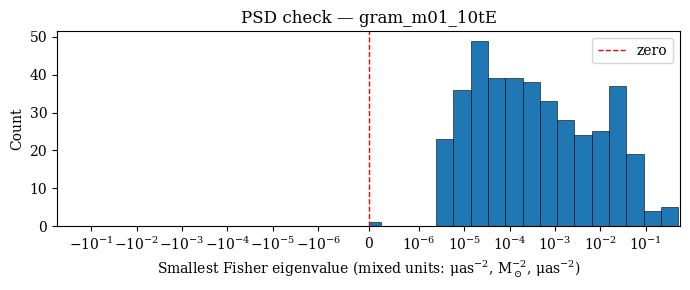

In [195]:
# ── Eigenvalue check: PSD verification ─────────────────────────────────────────
min_eigs = []
n_neg    = 0
for i, cmat in enumerate(cov_new):
    d   = np.sqrt(np.maximum(np.abs(np.diag(cmat)), 1e-300))
    Cc  = cmat / np.outer(d, d)
    F   = np.linalg.inv(Cc) / np.outer(d, d)
    eig = np.linalg.eigvalsh(F)
    min_eigs.append(eig[0])
    if eig[0] < -1e-10:
        n_neg += 1
        print(f"  row {i:3d}: min_eig = {eig[0]:.3e}  pos = {positions_new[i]}")

min_eigs = np.array(min_eigs)
print(f"\nTotal: {len(cov_new)} matrices — {n_neg} with negative eigenvalues")
print(f"Smallest eigenvalue overall: {min_eigs.min():.3e}")
if n_neg == 0:
    print("All Fisher matrices are positive semi-definite. ✓")
else:
    print("NOTE: negative eigenvalues may indicate near-caustic (degenerate) positions.")

linthresh = 1e-6
max_abs = np.nanmax(np.abs(min_eigs))
if max_abs <= linthresh:
    bins = np.linspace(-linthresh, linthresh, 31)
else:
    log_edges = np.logspace(np.log10(linthresh), np.log10(max_abs), 16)
    lin_edges = np.linspace(-linthresh, linthresh, 9)
    bins = np.unique(np.concatenate((-log_edges[::-1], lin_edges, log_edges)))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(min_eigs, bins=bins, edgecolor='k', linewidth=0.4)
ax.axvline(0, color='r', linestyle='--', linewidth=1, label='zero')
ax.set_xscale('symlog', linthresh=linthresh)
ax.set_xlabel(r"Smallest Fisher eigenvalue (mixed units: $\mu$as$^{-2}$, $M_\odot^{-2}$, $\mu$as$^{-2}$)")
ax.set_ylabel("Count")
ax.set_title(f"PSD check — {PREFIX}")
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, f"{PREFIX}_eigenvalues.pdf"), bbox_inches='tight')
plt.show()

In [196]:
# ── Combine II + magnification Fisher matrices ─────────────────────────────────
cov_combo, rad_combo, mass_combo, posx_combo, posy_combo = [], [], [], [], []
for i in range(len(fish_mag_new)):
    cc, unc = get_combo_cov(fish_mag_new[i], cov_new[i], theta_step_mag, theta_step, 1)
    cov_combo.append(cc)
    rad_combo .append(unc[0])
    mass_combo.append(unc[1])
    posx_combo.append(unc[2])
    posy_combo.append(unc[3])

rad_combo  = np.array(rad_combo)
mass_combo = np.array(mass_combo)
posx_combo = np.array(posx_combo)
posy_combo = np.array(posy_combo)

print(f"Combo uncertainties: {len(cov_combo)} positions")
print(f"  rad  range: {rad_combo.min():.3e} – {rad_combo.max():.3e} mas")
print(f"  mass range: {mass_combo.min():.3e} – {mass_combo.max():.3e} Msun")


Combo uncertainties: 400 positions
  rad  range: 1.742e-03 – 3.025e-02 mas
  mass range: 3.162e-02 – 1.100e+01 Msun


In [197]:
# ── Build rotated grid positions ───────────────────────────────────────────────
angle_rot   = -phi_0 + np.pi / 2
pos_rad     = positions_new / image_size           # normalise to [0, 1]
x_rot, y_rot = rotate_data_pos(pos_rad[:, 0], pos_rad[:, 1], angle_rot)
positions_rot = np.stack(
    [(-np.abs(x_rot)).ravel(), (np.abs(y_rot)).ravel()], axis=1
) * theta_step * image_size                        # back to radians

x_grid = np.unique(positions_rot[:, 0].round(15))
x_grid = np.concatenate((x_grid, -x_grid[-2::-1]))
y_grid = np.unique(positions_rot[:, 1].round(15))
y_grid = np.concatenate((-y_grid[::-1], y_grid[1:]))

print(f"One-quadrant grid: {n}x{n}  →  full grid: {len(x_grid)}x{len(y_grid)}")
print(f"Extent: x = [{x_grid.min()*rad_to_arcsec:.1f}, {x_grid.max()*rad_to_arcsec:.1f}] uas")
print(f"        y = [{y_grid.min()*rad_to_arcsec:.1f}, {y_grid.max()*rad_to_arcsec:.1f}] uas")


One-quadrant grid: 20x20  →  full grid: 39x39
Extent: x = [-8.1, 8.1] uas
        y = [-8.1, 8.1] uas


In [198]:
# ── Expand one-quadrant arrays to full 4-quadrant grid ─────────────────────────
rad_grid  = one_quad_to_full(rad_combo,      n)
mass_grid = one_quad_to_full(mass_combo,     n)
xpos_grid = one_quad_to_full(xpos_new,       n)   # raw II x uncertainty in μas
ypos_grid = one_quad_to_full(ypos_new,       n)   # raw II y uncertainty in μas
chi_grid  = one_quad_to_full(chis_combo_new, n)

print(f"Full grid shape: {rad_grid.shape}")

Full grid shape: (39, 39)


In [199]:
# ── Build RegularGridInterpolators ────────────────────────────────────────────
_kw = dict(bounds_error=False, method='linear', fill_value=np.nan)

rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid,  **_kw)
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, **_kw)
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, **_kw)
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, **_kw)
chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid,  **_kw)

# ── Interpolate onto a fine grid ──────────────────────────────────────────────
NFINE  = 200
fine_x = np.linspace(x_grid.min(), x_grid.max(), NFINE)
fine_y = np.linspace(y_grid.min(), y_grid.max(), NFINE)
Xf, Yf = np.meshgrid(fine_x, fine_y, indexing='ij')
pts    = np.stack([Xf.ravel(), Yf.ravel()], axis=-1)

rad_interp  = rad_spline (pts).reshape(Xf.shape)
mass_interp = mass_spline(pts).reshape(Xf.shape)
xpos_interp = xpos_spline(pts).reshape(Xf.shape)
ypos_interp = ypos_spline(pts).reshape(Xf.shape)
chi_interp  = chi_spline (pts).reshape(Xf.shape)

# convenience: extent and coordinate grids in micro-arcseconds
extent_uas = np.array([fine_x.min(), fine_x.max(), fine_y.min(), fine_y.max()]) * rad_to_arcsec
Xf_uas     = Xf * rad_to_arcsec
Yf_uas     = Yf * rad_to_arcsec
orig_map   = plt.cm.get_cmap('cividis')
rev_map    = orig_map.reversed()


/var/folders/4c/r0fv34l54990y0356vhxlw7c0000gn/T/ipykernel_41346/2907662103.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map   = plt.cm.get_cmap('cividis')


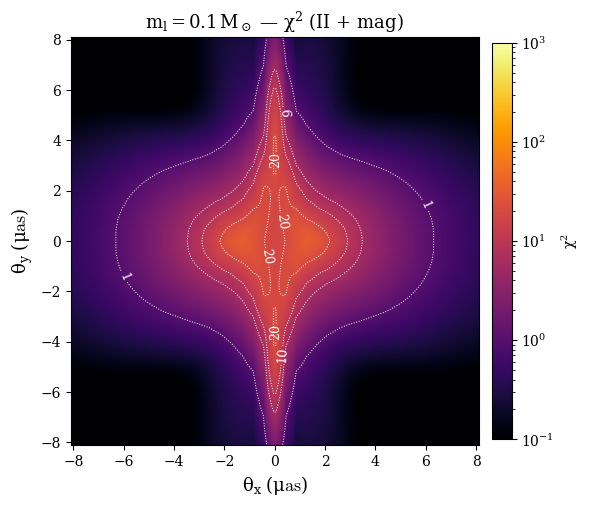

In [200]:
# ── 2D map: chi-squared ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 8))
Z = np.flipud(chi_interp).T
im = ax.imshow(Z, origin='lower', extent=extent_uas,
               cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=0.1, vmax=1000))
for lev, fmt in zip([1, 6, 10, 20], ['1', '6', '10', '20']):
    cs = ax.contour(Xf_uas.T, Yf_uas.T, Z, levels=[lev],
                    colors='white', linewidths=0.7, linestyles='dotted')
    ax.clabel(cs, fmt=fmt, fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.045, pad=0.03, label=r'$\chi^2$')
ax.set_xlabel(r'$\theta_x \ (\mu\mathrm{as})$', fontsize=13)
ax.set_ylabel(r'$\theta_y \ (\mu\mathrm{as})$', fontsize=13)
ax.set_title(rf'$m_l = {MASS}\,M_\odot$ — $\chi^2$ (II + mag)', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, f"{PREFIX}_chi2.pdf"), bbox_inches='tight')
plt.show()

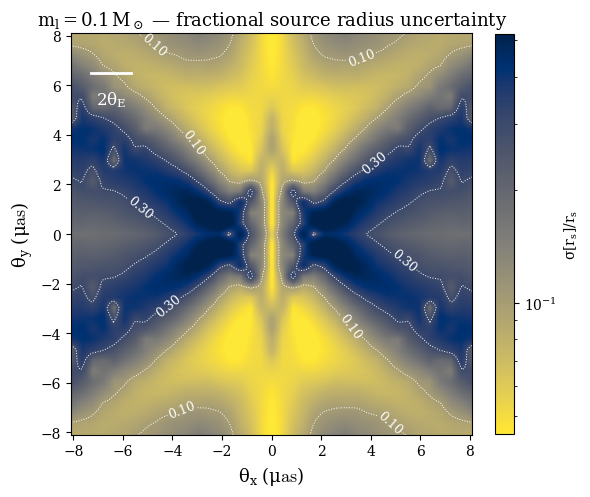

In [201]:
# ── 2D map: fractional source radius uncertainty sigma_r / r_s ────────────────
fig, ax = plt.subplots(figsize=(6, 8))
Z = np.flipud(rad_interp).T / rad_mas
_finite = Z[np.isfinite(Z)]
_vmin = np.nanpercentile(_finite, 2)
_vmax = np.nanpercentile(_finite, 98)
norm = matplotlib.colors.LogNorm(vmin=max(_vmin, 1e-2), vmax=min(_vmax, 1e3))
im = ax.imshow(Z, origin='lower', extent=extent_uas, cmap=rev_map, norm=norm)
for lev in [0.01, 0.03, 0.1, 0.3, 1.0, 10.0]:
    cs = ax.contour(Xf_uas.T, Yf_uas.T, Z, levels=[lev],
                    colors='white', linewidths=0.7, linestyles='dotted')
    ax.clabel(cs, fmt=f'{lev:.2f}', fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.045, label=r'$\sigma[r_s] / r_s$')

# theta_E scale bar (upper-left corner inside the image)
xmin_uas, xmax_uas = extent_uas[0], extent_uas[1]
ymin_uas, ymax_uas = extent_uas[2], extent_uas[3]
scale_uas = 2 * theta_E * rad_to_arcsec
x_bar = xmin_uas + 0.05 * (xmax_uas - xmin_uas)
y_bar = ymax_uas - 0.10 * (ymax_uas - ymin_uas)
ax.plot([x_bar, x_bar + scale_uas], [y_bar, y_bar], 'w-', lw=2)
ax.text(x_bar + scale_uas / 2, y_bar - 0.04 * (ymax_uas - ymin_uas),
        r'$2\theta_E$', ha='center', va='top', color='white', fontsize=12)

ax.set_xlabel(r'$\theta_x \ (\mu\mathrm{as})$', fontsize=13)
ax.set_ylabel(r'$\theta_y \ (\mu\mathrm{as})$', fontsize=13)
ax.set_title(rf'$m_l = {MASS}\,M_\odot$ — fractional source radius uncertainty', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, f"{PREFIX}_rad_frac.pdf"), bbox_inches='tight')
plt.show()

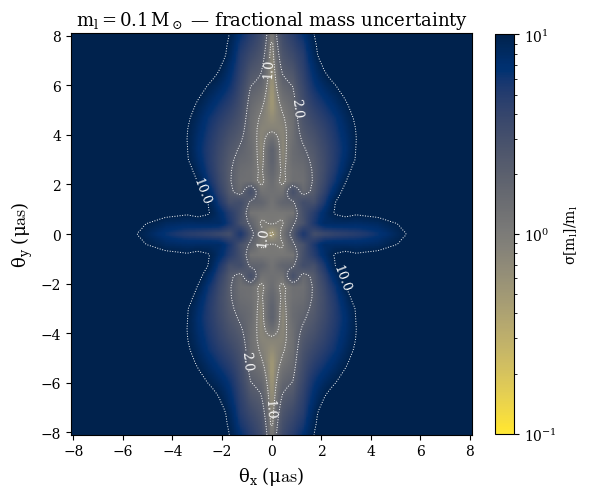

In [202]:
# ── 2D map: fractional mass uncertainty sigma_m / m_l ─────────────────────────
fig, ax = plt.subplots(figsize=(6, 8))
Z = np.flipud(mass_interp).T / MASS
im = ax.imshow(Z, origin='lower', extent=extent_uas, cmap=rev_map,
               norm=matplotlib.colors.LogNorm(vmin=0.1, vmax=10))
for lev in [0.5, 1.0, 2.0, 10.0]:
    cs = ax.contour(Xf_uas.T, Yf_uas.T, Z, levels=[lev],
                    colors='white', linewidths=0.7, linestyles='dotted')
    ax.clabel(cs, fmt=f'{lev:.1f}', fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.045, label=r'$\sigma[m_l] / m_l$')
ax.set_xlabel(r'$\theta_x \ (\mu\mathrm{as})$', fontsize=13)
ax.set_ylabel(r'$\theta_y \ (\mu\mathrm{as})$', fontsize=13)
ax.set_title(rf'$m_l = {MASS}\,M_\odot$ — fractional mass uncertainty', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, f"{PREFIX}_mass_frac.pdf"), bbox_inches='tight')
plt.show()

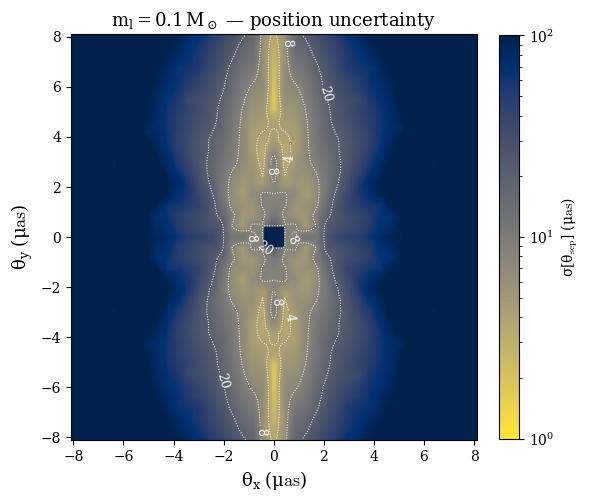

In [203]:
# ── 2D map: combined position uncertainty sqrt(sigma_x^2 + sigma_y^2) ─────────
fig, ax = plt.subplots(figsize=(6, 8))
Z = np.sqrt(np.flipud(xpos_interp).T**2 + np.flipud(ypos_interp).T**2)
im = ax.imshow(Z, origin='lower', extent=extent_uas, cmap=rev_map,
               norm=matplotlib.colors.LogNorm(vmin=1, vmax=100))
for lev in [4, 8, 20]:
    cs = ax.contour(Xf_uas.T, Yf_uas.T, Z, levels=[lev],
                    colors='white', linewidths=0.7, linestyles='dotted')
    ax.clabel(cs, fmt=f'{lev:.0f}', fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.045,
             label=r'$\sigma[\theta_\mathrm{sep}]\ (\mu\mathrm{as})$')
ax.set_xlabel(r'$\theta_x \ (\mu\mathrm{as})$', fontsize=13)
ax.set_ylabel(r'$\theta_y \ (\mu\mathrm{as})$', fontsize=13)
ax.set_title(rf'$m_l = {MASS}\,M_\odot$ — position uncertainty', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, f"{PREFIX}_pos.pdf"), bbox_inches='tight')
plt.show()